# Guía L1 — La factura de la ciudad · **Sesión 2: la CHEC aterriza en Londres**

**Cálculo Diferencial — Laboratorio computacional** · Universidad Nacional de Colombia, Sede Manizales

> La sesión 1 nos dejó una nube de miles de consumos y un movimiento: condicionar hasta que la relación se vuelva función. Hoy la nube se llena de pesos colombianos, y el movimiento se repite con plata.

**Antes de empezar:** copia propia del cuaderno, la tarea puente lista (la verificación reproducida) y **el recibo de energía de su casa** sobre la mesa.

---
## ⏸️ Momento 1 — Predecir

P4 y P5 están en la guía. **En papel, a mano.** La apuesta de P5 —¿la nube (consumo, valor) con todos los estratos revueltos pasa el test de la recta vertical?— es la protagonista de hoy. Foto al informe antes de seguir.

---
## 1 · La tarifa en vivo: nuestra primera API

La sesión pasada el mesero nos trajo un plato congelado. Hoy pedimos en vivo: la URL de abajo es un **pedido** al portal de datos abiertos del Estado colombiano (`datos.gov.co`), y la respuesta es el pliego tarifario oficial de la CHEC — el mismo que decide cuánto paga su casa.

Detalle de la casa: las APIs sirven porciones. Sin el `$limit`, el mesero trae solo las primeras 1.000 filas y uno ni se entera. Leer la documentación del dataset **es** parte de leer el dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RUTA_TARIFAS = "https://www.datos.gov.co/resource/c698-wqig.csv?$limit=60000"
# Si el wifi del laboratorio se cae, el monitor tiene la copia congelada (mismo formato):
# RUTA_TARIFAS = "https://raw.githubusercontent.com/cmorregof/labs-calculo-2026-2/main/datos/chec_tarifas_congeladas.csv"

tarifas = pd.read_csv(RUTA_TARIFAS)
print("Filas y columnas:", tarifas.shape)
print(list(tarifas.columns))

Filas y columnas: (40609, 24)
['costounitariotarifa_ano', 'costounitariotarifa_mes', 'comercializador_codigo', 'comercializador_nombre', 'mercado_codigo', 'mercado_nombre', 'costounitariotarifa_tipomed', 'nivel_tension_codigo', 'modalidadcobro_propiedad', 'claseservicio_codigo', 'claseservicio_descri', 'claseservicio_estrato', 'costounitariotarifa_rangoconsumo', 'costounitariotarifa_tipomercado', 'costounitariotarifa_generacion', 'costounitariotarifa_transmision', 'costounitariotarifa_distribucion', 'costounitariotarifa_comercializacion', 'costounitariotarifa_perdidas', 'costounitariotarifa_restricciones', 'costounitariotarifa_cu', 'costounitariotarifa_cureal', 'costounitariotarifa_subcon', 'costounitariotarifa_valor_tarifa']


In [2]:
# ✁ Ejercicio 1 — El ritual, ahora sin acompañamiento: mirar antes de cruzar.
# Este dataset tiene más columnas y más trampas que el de Londres. Respondan con código:
#   a) ¿Qué mercados (mercado_nombre) aparecen y con cuántas filas cada uno?
#   b) ¿Qué años cubre el pliego? (ojo: la columna de año puede venir como texto "2,026")
#   c) ¿Qué estratos residenciales hay y qué valores toma el "rango de consumo"?
#   d) ¿Hay NaN donde no debería haberlos? ¿Y cuál es el DOMINIO de valor_tarifa?

# Normalizamos el año y el valor de una vez:
tarifas["ano"] = tarifas["costounitariotarifa_ano"].astype(str).str.replace(",", "").astype(int)
tarifas["valor"] = pd.to_numeric(tarifas["costounitariotarifa_valor_tarifa"], errors="coerce")

print("a) Mercados y cantidad de filas")
print(tarifas["mercado_nombre"].value_counts())
print()

print("b) Años que cubre el pliego")
# Convertimos a tipo int nativo de Python para una visualización limpia
anos_limpios = [int(a) for a in sorted(tarifas["ano"].unique())]
print(anos_limpios)
print()

print("c) Estratos residenciales y rangos de consumo")
estratos_res = tarifas[tarifas["claseservicio_descri"].str.contains("Residencial", na=False, case=False)]
print("Estratos residenciales encontrados:", [int(e) for e in sorted(estratos_res["claseservicio_estrato"].dropna().unique())])
print("Valores del rango de consumo:", sorted([int(r) for r in tarifas["costounitariotarifa_rangoconsumo"].unique()]))
print()

print("d) Verificación de NaN y dominio de valor_tarifa")
print("NaN en 'año':", tarifas["ano"].isna().sum())
print("NaN en 'valor' (fallos de conversión):", tarifas["valor"].isna().sum())
print("Rango de valores (min, max) de valor_tarifa:", tarifas["valor"].min(), "-", tarifas["valor"].max())
print("Cantidad de valores ùnicos en tarifas (Dominio de la variable):", tarifas["valor"].nunique())

a) Mercados y cantidad de filas
mercado_nombre
CHEC       37683
PEREIRA     2926
Name: count, dtype: int64

b) Años que cubre el pliego
[2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]

c) Estratos residenciales y rangos de consumo
Estratos residenciales encontrados: [1, 2, 3, 4, 5, 6]
Valores del rango de consumo: [1, 2]

d) Verificación de NaN y dominio de valor_tarifa
NaN en 'año': 0
NaN en 'valor' (fallos de conversión): 0
Rango de valores (min, max) de valor_tarifa: 102.1672 - 1336.8041
Cantidad de valores ùnicos en tarifas (Dominio de la variable): 10288


---
## 2 · La tarifa como función: `valor_factura`

Del pliego a la **función definida por trozos** que decide cuánto paga una casa. Dos ingredientes reales:

- El **consumo de subsistencia** (CS): en Manizales (2.150 m; la norma fija el umbral en 1.000 m de altitud) son **130 kWh/mes** (173 kWh/mes por debajo de los 1.000 m). Hasta ahí, los estratos 1–3 pagan tarifa subsidiada; de ahí en adelante, todos pagan tarifa plena. Búsquenlo en su recibo.
- El **pliego del mes**: lo sacamos del dataset, no de un número inventado. (El pliego trae variantes por propiedad de la red y nivel de tensión; tomamos las condiciones más comunes y la *mediana* cuando queda más de un valor — decisión de modelación, y queda escrita.)

Escriban la función en notación de la clase antes de leer el código: para estrato $e \le 3$,

$$V_e(x) = \begin{cases} t^{sub}_e \, x & 0 \le x \le CS \\ t^{sub}_e \, CS + t^{pl}\,(x - CS) & x > CS \end{cases}$$

¿Y para $e \ge 4$? ¿Es continua $V_e$ en $x = CS$? ¿Es derivable ahí? (Guarden la segunda pregunta: vuelve en el curso.)

In [3]:
ANO_TARIFA, MES_TARIFA = 2026, 8   # el pliego que usaremos para cobrar (el más reciente)
CS = 130                            # kWh/mes de subsistencia para alturas >= 1000 m (Manizales: 2.150 m)

base = tarifas[(tarifas["mercado_nombre"] == "CHEC") &
               (tarifas["costounitariotarifa_tipomercado"] == "R") &
               (tarifas["nivel_tension_codigo"] == 1) &
               (tarifas["modalidadcobro_propiedad"] == "0% OR") &
               (tarifas["ano"] == ANO_TARIFA) &
               (pd.to_numeric(tarifas["costounitariotarifa_mes"]) == MES_TARIFA) &
               (tarifas["claseservicio_descri"].str.contains("Residencial Estrato", na=False))]

pliego = base.pivot_table(index="claseservicio_estrato",
                          columns="costounitariotarifa_rangoconsumo",
                          values="valor", aggfunc="median")
pliego.columns = ["subsidiada", "plena"][:len(pliego.columns)]
print("Pliego CHEC", ANO_TARIFA, "-", MES_TARIFA, "($/kWh):")
print(pliego.round(2))

def valor_factura(kwh, estrato):
    """Valor de la energía de un mes (sin cargo fijo, sin alumbrado): función por trozos."""
    t_sub = pliego.loc[estrato, "subsidiada"]
    t_plena = pliego.loc[estrato, "plena"] if not pd.isna(pliego.loc[estrato].get("plena", np.nan)) else t_sub
    if estrato <= 3:
        basico = min(kwh, CS) * t_sub       # el tramo subsidiado, hasta el CS
        resto  = max(kwh - CS, 0) * t_plena  # el resto, a tarifa plena
        return basico + resto
    else:
        return kwh * t_sub                   # estratos 4-6: un solo precio (4: pleno; 5-6: con contribución)

for kwh in [100, 130, 200, 300]:
    print(f"Estrato 3, {kwh} kWh → ${valor_factura(kwh, 3):,.0f}")

Pliego CHEC 2026 - 8 ($/kWh):
                       subsidiada   plena
claseservicio_estrato                    
1.0                        422.62  894.58
2.0                        528.28  894.58
3.0                        760.40  894.58
4.0                        894.58     NaN
5.0                       1073.50     NaN
6.0                       1073.50     NaN
Estrato 3, 100 kWh → $76,040
Estrato 3, 130 kWh → $98,852
Estrato 3, 200 kWh → $161,473
Estrato 3, 300 kWh → $250,931


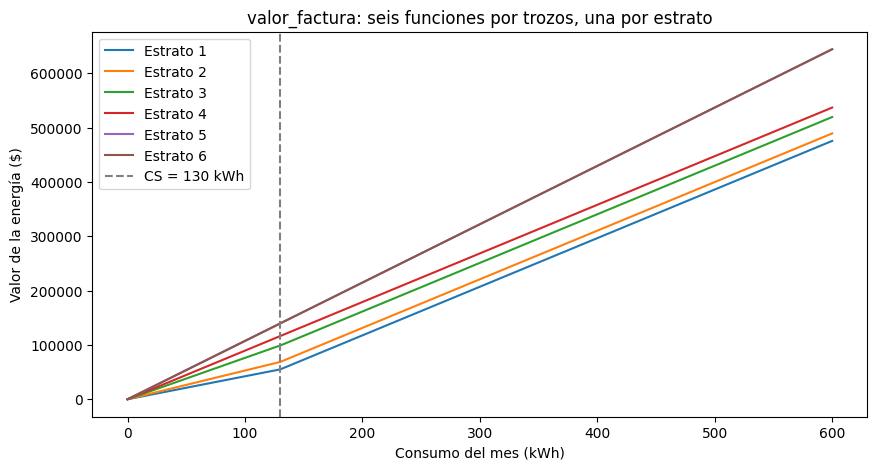

En los estratos 1 y 2 se pueden el codo cuando se llega a los 130 Kwh, en el resto de estratos no se aprecia o no hay de por si
La pendiente en ambos casos para todos los estratos aumenta progresivamente, la diferencia clara que se nota antes de los 130 Kwh es que el aumento del valor aumenta pero no taan exageradamente como despúes de consumir los 130 Kwh


In [4]:
# Seis curvas, una por estrato: la función por trozos, dibujada.
x = np.linspace(0, 600, 601)
plt.figure(figsize=(10, 5))
for e in range(1, 7):
    plt.plot(x, [valor_factura(k, e) for k in x], label=f"Estrato {e}")
plt.axvline(CS, linestyle="--", color="gray", label=f"CS = {CS} kWh")
plt.xlabel("Consumo del mes (kWh)"); plt.ylabel("Valor de la energía ($)")
plt.title("valor_factura: seis funciones por trozos, una por estrato")
plt.legend(); plt.show()

# 🗣️ ¿En qué estratos hay un 'codo' y en cuáles no? ¿Qué pasa con la pendiente antes y después del CS?
print("En los estratos 1 y 2 se pueden el codo cuando se llega a los 130 Kwh, en el resto de estratos no se aprecia o no hay de por si")
print("La pendiente en ambos casos para todos los estratos aumenta progresivamente, la diferencia clara que se nota antes de los 130 Kwh es que el aumento del valor aumenta pero no taan exageradamente como despúes de consumir los 130 Kwh")

In [5]:
# ✏️ Ejercicio 2 — La auditoría del recibo.
# Con el recibo de un integrante: consumo del mes (kWh), estrato, y valor pagado por ENERGÍA.
kwh_recibo   = 82      # ← su recibo
estrato_casa = 4      # ← su estrato
pago_real    = 77442      # ← lo que dice el recibo

print(f"El modelo dice: ${valor_factura(kwh_recibo, estrato_casa):,.0f}  |  El recibo dice: ${pago_real:,.0f}")

# 🗣️ ¿El modelo reproduce, aproximadamente, lo que su casa pagó? ¿Qué explica la diferencia?
#    (cargo fijo, alumbrado público, contribución, el mes del pliego...). Acaban de auditar
#    su propio modelo contra la realidad — anoten el veredicto.
print("Utilizando una factura diferente a la de la predicción:")
print("Nuestra factura de muestra es de hace un año, el precio respecto al modelo es parecido al precio original")
print("La diferencia entre uno y otro puede ser que se notaria en el mes del pliego, debido a los datos actualizados a dia de hoy contra los datos del recibo de hace un año, siendo el factor principal de la diferencia")

El modelo dice: $73,356  |  El recibo dice: $77,442
Utilizando una factura diferente a la de la predicción:
Nuestra factura de muestra es de hace un año, el precio respecto al modelo es parecido al precio original
La diferencia entre uno y otro puede ser que se notaria en el mes del pliego, debido a los datos actualizados a dia de hoy contra los datos del recibo de hace un año, siendo el factor principal de la diferencia


---
## 3 · La decisión de modelación: ¿qué estrato le toca a Londres?

Para cobrarle a un hogar londinense necesitamos asignarle un estrato — y eso es **supuesto nuestro**, no dato. Abajo hay un criterio de ejemplo (cuantiles de consumo, con proporciones parecidas a las de Manizales). Su equipo puede adoptarlo o cambiarlo, pero sea cual sea el criterio: **se defiende por escrito en tres líneas**. No hay criterio “correcto”; hay criterios defendibles y criterios que no se pensaron.

In [6]:
# Cargamos Londres: la copia congelada de la sesión 1 (consumo MENSUAL por hogar).
RUTA = "https://raw.githubusercontent.com/cmorregof/labs-calculo-2026-2/main/datos/londres_mensual.csv"
df = pd.read_csv(RUTA)
print("Filas:", len(df), "| hogares:", df["hogar"].nunique())

# ✏️ Criterio de ejemplo (cámbienlo si quieren): el estrato se asigna POR HOGAR según su consumo
# mediano en todo el estudio (un hogar no cambia de estrato de un mes a otro).
consumo_hogar = df.groupby("hogar")["kwh"].median()
cortes = consumo_hogar.quantile([0, .25, .50, .70, .85, .95, 1.0]).values
estrato_hogar = pd.cut(consumo_hogar, bins=cortes, labels=[3, 4, 2, 1, 5, 6], include_lowest=True).astype(int)
df["estrato"] = df["hogar"].map(estrato_hogar)
print(estrato_hogar.value_counts().sort_index())

# 🗣️ Defensa del criterio (tres líneas, aquí): ¿por qué ESTE reparto y no otro?
print("Escogimos estos supuestos valores de estratos en Londres debido a que este al pertenecer a un país de primer mundo, los estratos deberían estar en un")
print("promedio entre 3 y 4,  en donde hay más personas viviendo comodamente, mientras hay otras cuántas que no obtienen lo suficiente (en su mayoría inmigrantes), ")
print("y otros pocos con lo suficiente para estar en estrato 5 - 6 ya que mundialmente la cantidad de personas de este rango se ve muy reducida respecto a otras.")

Filas: 113440 | hogares: 5556
kwh
1     833
2    1111
3    1389
4    1389
5     556
6     278
Name: count, dtype: int64
Escogimos estos supuestos valores de estratos en Londres debido a que este al pertenecer a un país de primer mundo, los estratos deberían estar en un
promedio entre 3 y 4,  en donde hay más personas viviendo comodamente, mientras hay otras cuántas que no obtienen lo suficiente (en su mayoría inmigrantes), 
y otros pocos con lo suficiente para estar en estrato 5 - 6 ya que mundialmente la cantidad de personas de este rango se ve muy reducida respecto a otras.


---
## 4 · La nube: la ciudad facturada

Aplicamos `valor_factura` a los 113.440 pares (hogar, mes) y graficamos **(consumo, valor)**. Primero todos los estratos revueltos; relean P5 antes de correr la celda.

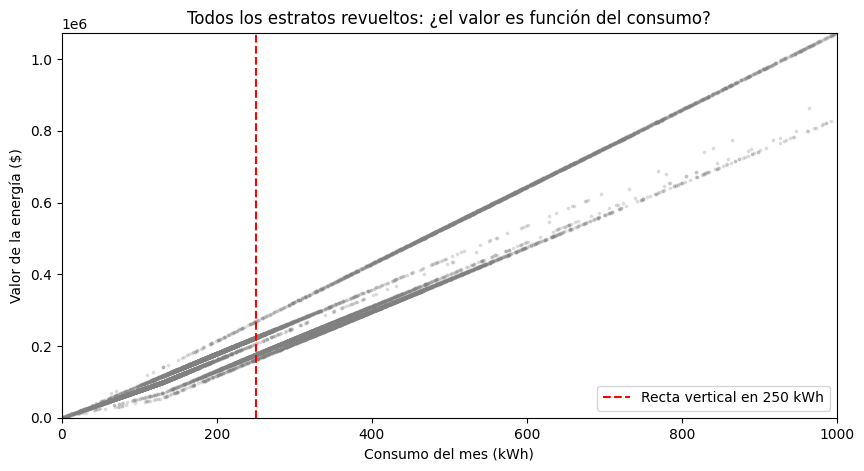

Hogares con consumo ≈ 250 kWh: 530 | valores distintos que pagan: 330
estrato
1    162372.0
2    176071.0
3    206273.0
4    223481.0
5    268848.0
6    268231.0
Name: valor, dtype: float64


In [7]:
df["valor"] = [valor_factura(k, e) for k, e in zip(df["kwh"], df["estrato"])]

muestra = df.sample(min(20000, len(df)), random_state=1)
plt.figure(figsize=(10, 5))
plt.scatter(muestra["kwh"], muestra["valor"], s=3, alpha=0.2, color="gray")
X0 = 250
plt.axvline(X0, color="red", linestyle="--", linewidth=1.5, label=f"Recta vertical en {X0} kWh")
plt.xlim(0, 1000); plt.ylim(0, valor_factura(1000, 6))
plt.xlabel("Consumo del mes (kWh)"); plt.ylabel("Valor de la energía ($)")
plt.title("Todos los estratos revueltos: ¿el valor es función del consumo?")
plt.legend(); plt.show()

cerca = df[(df["kwh"] > X0 - 1) & (df["kwh"] < X0 + 1)]
print(f"Hogares con consumo ≈ {X0} kWh: {len(cerca)} | valores distintos que pagan: {cerca['valor'].round(0).nunique()}")
print(cerca.groupby("estrato")["valor"].median().round(0))

🗣️ **La recta roja atraviesa la nube ¿en cuántos puntos?** Un mismo consumo, varios valores. Entonces, revueltos, el valor **no** es función solo del consumo: falta una variable en el dominio. ¿Cuál? Escríbanlo con la definición formal (dominio, codominio, regla) y confronten P5.

Ahora el movimiento de la sesión 1, con plata: **condicionar por estrato**.

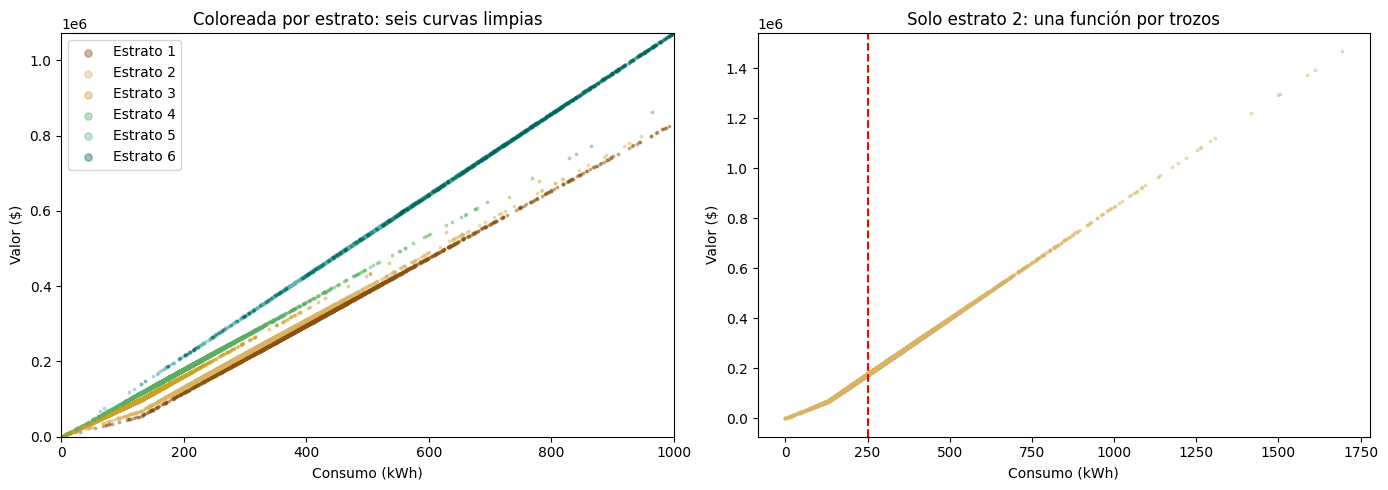

Estrato 2, consumo ≈ 250 kWh: 232 hogares, ¿cuántos valores distintos? Miren:
        kwh     valor
265   250.0  176008.8
580   249.5  175615.2
955   249.7  175731.5
1340  250.8  176760.3
1414  249.1  175230.5
3091  250.8  176706.6
4002  249.4  175481.0
4038  250.2  176169.8


In [12]:
colores = {1: "#8c510a", 2: "#d8b365", 3: "#c9a227", 4: "#5aae61", 5: "#5ab4ac", 6: "#01665e"}
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for e in range(1, 7):
    sub = muestra[muestra["estrato"] == e]
    ax[0].scatter(sub["kwh"], sub["valor"], s=3, alpha=0.4, color=colores[e], label=f"Estrato {e}")
ax[0].set_xlim(0, 1000); ax[0].set_ylim(0, valor_factura(1000, 6))
ax[0].set_title("Coloreada por estrato: seis curvas limpias"); ax[0].legend(markerscale=3)
ax[0].set_xlabel("Consumo (kWh)"); ax[0].set_ylabel("Valor ($)")

# ✏️ Ejercicio 3 — Un solo estrato. Cambien E y comprueben con código que ahora sí es función:
E = 2
uno = df[df["estrato"] == E]
ax[1].scatter(uno["kwh"], uno["valor"], s=3, alpha=0.4, color=colores[E])
ax[1].axvline(X0, color="red", linestyle="--")
ax[1].set_title(f"Solo estrato {E}: una función por trozos")
ax[1].set_xlabel("Consumo (kWh)"); ax[1].set_ylabel("Valor ($)")
plt.tight_layout(); plt.show()

cerca_E = uno[(uno["kwh"] > X0 - 1) & (uno["kwh"] < X0 + 1)]
print(f"Estrato {E}, consumo ≈ {X0} kWh: {len(cerca_E)} hogares, ¿cuántos valores distintos? Miren:")
print(cerca_E[["kwh", "valor"]].head(8).round(1))
# 🗣️ Los valores casi coinciden pero no exactamente: ¿por qué? (Pista: 'consumo ≈ 250' no es 'consumo = 250'.)
# Porque el consumo de los hogares no es exactamente de 250 Kwh, sino que va variando de poco a poco
# al variar el consumo, la fórmula matemática asigna valores ligeramente distintos a cada hogar de acuerdo con la pendiente de la función
#    ¿Qué tendrían que fijar para que la recta vertical atraviese EXACTAMENTE un punto?
# Tendriamos que fijar el valor del consumo en un punto exacto (como exactamente 250 Kwh) y no en un rango aproximado

🗣️ **Conclusión del movimiento, ahora con dinero:** al condicionar por estrato, la relación (consumo, valor) **se volvió** función, porque: *(dominio, codominio, regla)*. Y una pregunta para el informe: ¿cuál sería el dominio correcto de $V$ si quisiéramos que fuera función *sin* condicionar? (Pista: pares.)

Debe ser un conjunto de pares ordenados que incluyan el consumo de energía y el estrato social

---
## 5 · Cuantificar: el mismo aumento no cuesta lo mismo

Un hogar de estrato 3 aumenta su consumo en 25 kWh. ¿Cuánto más paga? Depende de **dónde** estaba.

In [26]:
# ✏️ Ejercicio 4 — Dos aumentos iguales, dos cobros distintos.
for a, b in [(100, 125), (135, 160), (120, 145)]:
    delta = valor_factura(b, 3) - valor_factura(a, 3)
    print(f"Estrato 3, de {a} a {b} kWh (+{b-a} kWh): paga ${delta:,.0f} más  →  ${delta/(b-a):,.1f} por cada kWh adicional")

# 🗣️ ¿Por qué no es lo mismo, si el aumento de consumo fue igual? Expliquen con los tramos y con el CS.
print("1. No cuesta lo mismo porque los aumentos ocurren en distintos tramos de la tarifa por trozos:")
print("El primer intervalo (100 a 125 kWh) ocurre completamente por debajo del CS (130 kWh), pagando tarifa subsidiada.")
print("El segundo intervalo (135 a 160 kWh) ocurre completamente por encima del CS, pagando tarifa plena por cada kWh adicional.")
print("El tercer intervalo (120 a 145 kWh) cruza el CS; los primeros 10 kWh se pagan con subsidio y los siguientes 15 kWh a tarifa plena.")
print("----------------------------------------------------------------------------------------------------------------------------------")

#    El cociente 'pesos adicionales / kWh adicional' tiene nombre en este curso: ¿cuál? ¿Es constante en cada tramo?
print("2. El nombre es: 'La razón de cambio promedio'. En cada tramo individual es constante porque la función es lineal en cada trozo.")
print("----------------------------------------------------------------------------------------------------------------------------------")

#    ¿Qué pasa con ese cociente en el tercer intervalo, el que CRUZA el CS? ¿Es 'la pendiente' de algo?
print("3. En el intervalo que cruza el CS, este cociente no es la pendiente de un solo tramo, sino la pendiente de la secante que une los puntos (120, V(120)) y (145, V(145)).")
print("----------------------------------------------------------------------------------------------------------------------------------")

# ✏️ Repitan para estrato 5: ¿cambia el cociente entre los dos intervalos? ¿Por qué?

for a, b in [(100, 125), (135, 160), (120, 145)]:
    delta_e5 = valor_factura(b, 5) - valor_factura(a, 5)
    print(f"Estrato 5, de {a} a {b} kWh (+{b-a} kWh): paga ${delta_e5:,.0f} más  →  ${delta_e5/(b-a):,.1f} por cada kWh adicional")

print("En el estrato 5, el cociente no cambia entre los intervalos. Es siempre $1,073.5 por kWh.")
print("Esto se debe a que para este estrato no aplica el subsidio por Consumo de Subsistencia (CS); la tarifa es única y lineal en todo su dominio.")


Estrato 3, de 100 a 125 kWh (+25 kWh): paga $19,010 más  →  $760.4 por cada kWh adicional
Estrato 3, de 135 a 160 kWh (+25 kWh): paga $22,365 más  →  $894.6 por cada kWh adicional
Estrato 3, de 120 a 145 kWh (+25 kWh): paga $21,023 más  →  $840.9 por cada kWh adicional
1. No cuesta lo mismo porque los aumentos ocurren en distintos tramos de la tarifa por trozos:
El primer intervalo (100 a 125 kWh) ocurre completamente por debajo del CS (130 kWh), pagando tarifa subsidiada.
El segundo intervalo (135 a 160 kWh) ocurre completamente por encima del CS, pagando tarifa plena por cada kWh adicional.
El tercer intervalo (120 a 145 kWh) cruza el CS; los primeros 10 kWh se pagan con subsidio y los siguientes 15 kWh a tarifa plena.
----------------------------------------------------------------------------------------------------------------------------------
2. El nombre es: 'La razón de cambio promedio'. En cada tramo individual es constante porque la función es lineal en cada trozo.
---------

In [29]:
# La matriz de correlación: la covariación resumida en un número.
numericas = df[["kwh", "valor", "estrato"]]
print(numericas.corr().round(3))

# 🗣️ ¿Qué mide la correlación entre kwh y valor? ¿Por qué es alta pero NO es 1, si dentro de cada
#    estrato el valor es función del consumo? ¿Qué NO mide la correlación? (Pista: ¿detectaría una
#    relación en forma de U?) La correlación es la covariación — nuestro concepto rector — resumida
#    en un solo valor entre -1 y 1.

print("1. Mide la fuerza y dirección de la relación lineal entre el consumo (kwh) y el costo de la factura (valor).")
print("------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------")
print("2. La correlación es alta pero no es 1 porque la correlación se calcula sobre toda la nube de datos revuelta (sin condicionar por estrato).")
print("Aunque cada estrato se comporta linealmente de forma interna, las tarifas (pendientes y subsidios) son distintas entre estratos.")
print("Al mezclarlos todos, los puntos no se alinean sobre una sola línea recta perfecta, lo que reduce la correlación ligeramente por debajo de 1.")
print("------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------")
print("3. La correlación solo detecta y mide relaciones lineales. No mide relaciones de tipo no lineal.")
print("Si la relación tuviera forma de 'U', la correlación lineal podría ser cercana a 0, fallando en detectar la dependencia matemática real entre las variables.")

           kwh  valor  estrato
kwh      1.000  0.985    0.274
valor    0.985  1.000    0.424
estrato  0.274  0.424    1.000
1. Mide la fuerza y dirección de la relación lineal entre el consumo (kwh) y el costo de la factura (valor).
------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
2. La correlación es alta pero no es 1 porque la correlación se calcula sobre toda la nube de datos revuelta (sin condicionar por estrato).
Aunque cada estrato se comporta linealmente de forma interna, las tarifas (pendientes y subsidios) son distintas entre estratos.
Al mezclarlos todos, los puntos no se alinean sobre una sola línea recta perfecta, lo que reduce la correlación ligeramente por debajo de 1.
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

---
## 6 · El microdataset del curso

Cada estudiante sube **una fila** a la tabla compartida del curso: `(codigo_anonimo, mes, kwh, valor_pagado, estrato)` — su recibo, anonimizado.

🗣️ Discutan 10 minutos: ¿por qué la tabla tiene *esas* columnas y no otras? ¿Qué preguntas futuras permite responder esa estructura y cuáles cierra? Elegir la estructura de una tabla es decidir qué se va a poder preguntar — eso también es matemáticas.

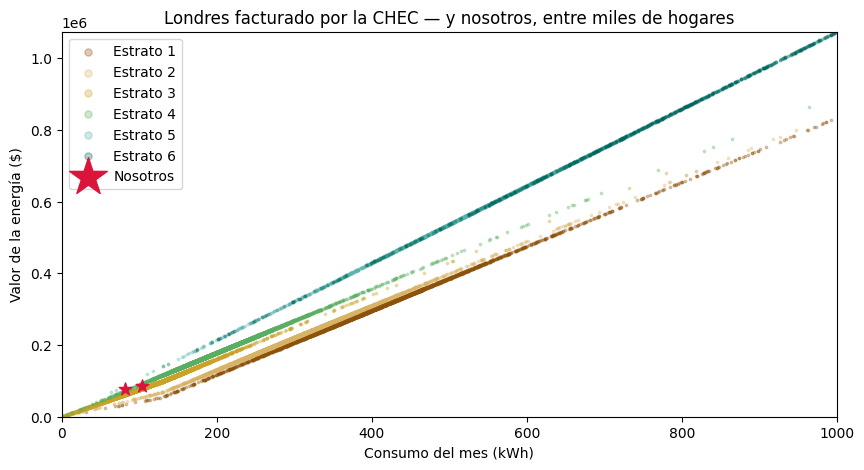

1. ¿Nuestros puntos caen exactamente sobre la curva de nuestro estrato?
No de forma exacta. Por ejemplo, para 82 kWh en Estrato 4, la función pura de energía calcula $73,356, mientras que el recibo real pagó $77,442. El punto queda ligeramente desplazado.
------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
2. ¿Por qué ocurre esta diferencia?
El recibo real incluye cobros adicionales que no dependen del consumo de energía, tales como el cargo fijo, alumbrado público, etc.
El pliego tarifario del modelo está actualizado en alguno de estos últimos meses, mientras que nuestros recibos físicos reales son de períodos anteriores donde el costo del kWh variaba respecto al modelo.


In [33]:
# La nube final: Londres facturado por la CHEC, con nosotros adentro.
plt.figure(figsize=(10, 5))
for e in range(1, 7):
    sub = muestra[muestra["estrato"] == e]
    plt.scatter(sub["kwh"], sub["valor"], s=3, alpha=0.3, color=colores[e], label=f"Estrato {e}")

# ✏️ Los puntos del curso (llenen con las filas del microdataset — kWh y valor por energía):
curso_kwh   = [82, 104]
curso_valor = [77442, 85595]
plt.scatter(curso_kwh, curso_valor, s=90, marker="*", color="crimson", zorder=3, label="Nosotros")

plt.xlim(0, 1000); plt.ylim(0, valor_factura(1000, 6))
plt.xlabel("Consumo del mes (kWh)"); plt.ylabel("Valor de la energía ($)")
plt.title("Londres facturado por la CHEC — y nosotros, entre miles de hogares")
plt.legend(markerscale=3); plt.show()

# 🗣️ Ahí estamos, del otro lado del océano. ¿Nuestros puntos caen sobre la curva de su estrato? Si no, ¿por qué?
print("1. ¿Nuestros puntos caen exactamente sobre la curva de nuestro estrato?")
print("No de forma exacta. Por ejemplo, para 82 kWh en Estrato 4, la función pura de energía calcula $73,356, mientras que el recibo real pagó $77,442. El punto queda ligeramente desplazado.")
print("------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------")
print("2. ¿Por qué ocurre esta diferencia?")
print("El recibo real incluye cobros adicionales que no dependen del consumo de energía, tales como el cargo fijo, alumbrado público, etc.")
print("El pliego tarifario del modelo está actualizado en alguno de estos últimos meses, mientras que nuestros recibos físicos reales son de períodos anteriores donde el costo del kWh variaba respecto al modelo.")

---
## 🗣️ Momento 3 — Explicar

Una página del equipo, aquí mismo: las dos discrepancias más interesantes entre predicción y resultado (P4, P5); la defensa del criterio de estratificación; y una reflexión de tres líneas sobre **qué fue real y qué fue supuesto** en todo lo que hicieron.

---
## 🤖 Protocolo de IA (recordatorio)

Las tres reglas del curso, siempre: intento propio antes de consultar; la IA no es la autoridad final; todo uso va a la bitácora individual. La **cacería puntuable** está en la guía: pídanle a una IA una función de Python que calcule la factura de energía con tarifas colombianas, *sin* darle el pliego, y audítenla contra la suya: ¿inventó valores? ¿cobró dos veces el tramo básico? ¿ignoró el estrato? ¿acertó el consumo de subsistencia de Manizales? Documenten el veredicto.

**Prohibido:** pedirle el criterio de estratificación, las conclusiones de los momentos 3, o el informe. Todo integrante debe poder explicar cualquier celda si el monitor la señala.

**Entregables** (cierre de esta semana): cuaderno `L1_apellidos.ipynb` ejecutado de arriba a abajo sin errores, con las predicciones fotografiadas y los tres momentos de ambas sesiones; bitácora de IA individual; la fila de cada estudiante en el microdataset; la tarea puente.